# 03 — Feature selection

Starting from the IV table of notebook 02, we choose the variables for the scorecard. Each filter asks a different question:

1. **IV filter:** does the variable separate goods from bads at all? (keep IV ≥ 0.02; flag IV < 0.1 as weak)
2. **Correlation filter:** do two variables tell the same story? (|r| > 0.7 → keep the one with higher IV)
3. **VIF filter:** can a variable be predicted from a *combination* of the others? (drop the highest VIF while > 5)
4. **Size cap:** keep at most 12 variables, choosing the highest IV.

All filters use the **WoE-transformed training data**. Run `02_binning_woe.ipynb` first.

In [1]:
import logging
import warnings

import pandas as pd
import matplotlib.pyplot as plt

logging.basicConfig(level=logging.INFO, format="%(levelname)s %(name)s: %(message)s", force=True)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
RATE_FORMAT = {"default_rate": "{:.1%}", "share": "{:.1%}", "woe": "{:+.3f}", "iv": "{:.4f}"}

from scorecard.data import PROCESSED_DIR, REPORTS_DIR
from scorecard.features import FEATURE_REASONS, FEATURE_TYPES
from scorecard.plots import plot_correlation_heatmap
from scorecard.selection import (
    cap_by_iv,
    compare_feature_sets,
    drop_correlated,
    drop_high_vif,
    filter_by_iv,
    selection_table,
)

train_woe = pd.read_csv(PROCESSED_DIR / "train_woe.csv")
ivs = pd.read_csv(REPORTS_DIR / "iv_table.csv")
iv = ivs.set_index("variable")["iv"]
steps = {"Candidates": len(iv)}

## Step 1: IV filter

Variables with IV below 0.02 carry almost no information, and adding them would only add noise.
Variables between 0.02 and 0.1 are kept but **flagged as weak**: they may still add something alongside the strong ones,
but they shouldn't be relied on.

In [2]:
iv_filter = filter_by_iv(iv)
after_iv = iv_filter.index[iv_filter["kept"]].tolist()
steps["After IV filter"] = len(after_iv)
iv_filter.style.format({"iv": "{:.3f}"})

INFO scorecard.selection: IV filter: keep avg_util_6m but flag as weak (IV 0.095 < 0.10)


INFO scorecard.selection: IV filter: keep pay_amt5 but flag as weak (IV 0.090 < 0.10)


INFO scorecard.selection: IV filter: keep util_trend but flag as weak (IV 0.078 < 0.10)


INFO scorecard.selection: IV filter: keep max_util_6m but flag as weak (IV 0.061 < 0.10)


INFO scorecard.selection: IV filter: keep util_1 but flag as weak (IV 0.060 < 0.10)


...

INFO scorecard.selection: IV filter: drop bill_amt3 (IV 0.005 < 0.02)


INFO scorecard.selection: IV filter: drop bill_amt5 (IV 0.004 < 0.02)


INFO scorecard.selection: IV filter: drop bill_amt4 (IV 0.004 < 0.02)


INFO scorecard.selection: IV filter: 22 of 30 variables kept


,iv,kept,weak
variable,,,
pay_1,0.894,True,False
months_delinquent_6m,0.878,True,False
max_delinquency_6m,0.792,True,False
pay_2,0.557,True,False
pay_3,0.420,True,False
pay_4,0.368,True,False
pay_5,0.343,True,False
pay_6,0.296,True,False
months_zero_payment_6m,0.263,True,False


**30 → 22.** Dropped: `age`, `education` and all six raw `bill_amt` columns.
Flagged weak: the utilisation variables and `pay_amt5`.

## Step 2: Correlation filter

If two variables move together almost perfectly, the model can't tell which one deserves the credit. Their coefficients
become unstable and can even get the wrong sign. We keep the one with the higher IV.

We go down the list **from the highest IV** and keep each variable unless it is too correlated with one already kept.
This way every drop is justified by a stronger variable that stays.

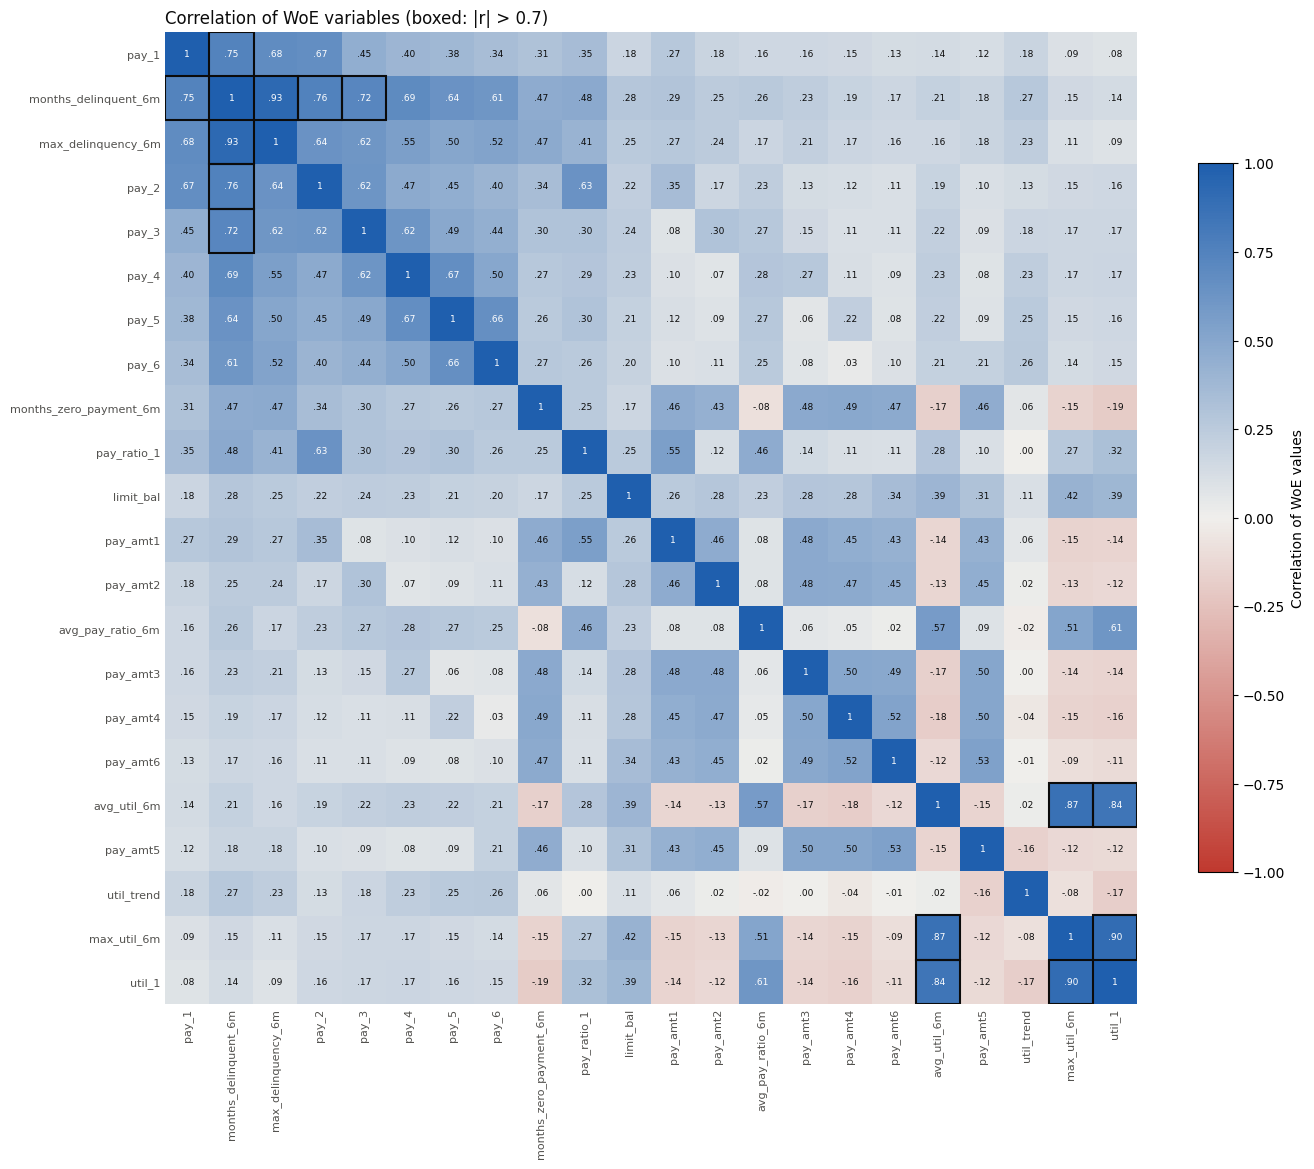

In [3]:
corr = train_woe[after_iv].corr()
plot_correlation_heatmap(corr, threshold=0.7)
plt.show()

In [4]:
after_corr, corr_decisions = drop_correlated(train_woe[after_iv], iv, threshold=0.7)
steps["After correlation filter"] = len(after_corr)
corr_decisions.style.format({"correlation": "{:.2f}"})

INFO scorecard.selection: Correlation filter: drop months_delinquent_6m (r = 0.75 with pay_1; IV 0.878 < 0.894)


INFO scorecard.selection: Correlation filter: drop max_util_6m (r = 0.87 with avg_util_6m; IV 0.061 < 0.095)


INFO scorecard.selection: Correlation filter: drop util_1 (r = 0.84 with avg_util_6m; IV 0.060 < 0.095)


INFO scorecard.selection: Correlation filter: 19 of 22 variables kept


,dropped,kept_instead,correlation,reason
0,months_delinquent_6m,pay_1,0.75,r = 0.75 with pay_1; IV 0.878 < 0.894
1,max_util_6m,avg_util_6m,0.87,r = 0.87 with avg_util_6m; IV 0.061 < 0.095
2,util_1,avg_util_6m,0.84,r = 0.84 with avg_util_6m; IV 0.060 < 0.095


**22 → 19.** The heatmap explains each drop:
- `months_delinquent_6m` overlaps with `pay_1` (r = 0.75). Their IVs are nearly equal (0.878 vs 0.894); `pay_1` wins.
- `max_util_6m` and `util_1` repeat `avg_util_6m` (r = 0.87 and 0.84). The average is the strongest of the three.
- The monthly `pay_x` columns correlate with their neighbours at about 0.5–0.67, just under the threshold, so they all survive.
  Keep that in mind for Step 4.

## Step 3: VIF filter

Correlation only looks at **pairs**. A variable can be almost fully explained by *several* others together,
even if no single pair is above 0.7. The **Variance Inflation Factor** measures this: VIF = 1 / (1 − R²), where R² is how well the
other variables predict it. VIF 5 means 80% of it is already explained by the rest.

In [5]:
after_vif, vif_steps = drop_high_vif(train_woe[after_corr], max_vif=5)
steps["After VIF filter"] = len(after_vif)
vif_steps.style.format({"vif": "{:.2f}"})

INFO scorecard.selection: VIF filter: highest VIF is pay_2 (3.69) <= 5.0, stop


INFO scorecard.selection: VIF filter: 19 of 19 variables kept


,step,variable,vif,dropped
0,1,pay_2,3.69,False


**19 → 19.** The highest VIF is `pay_2` at about 3.7, comfortably below 5. The correlation filter already removed the worst
overlaps, so no variable is explained by a combination of the others.

## Step 4: Size cap (at most 12)

Nineteen variables is more than a scorecard needs. Every extra variable is one more thing to monitor, explain to customers and
regulators, and keep stable over time. The simplest rule is to keep the 12 with the highest IV.

In [6]:
final = cap_by_iv(after_vif, iv, max_variables=12)
steps["After size cap"] = len(final)
pd.Series(steps, name="variables remaining").to_frame()

INFO scorecard.selection: IV cap: drop avg_pay_ratio_6m (IV 0.151, rank > 12)


INFO scorecard.selection: IV cap: drop pay_amt3 (IV 0.131, rank > 12)


INFO scorecard.selection: IV cap: drop pay_amt4 (IV 0.106, rank > 12)


INFO scorecard.selection: IV cap: drop pay_amt6 (IV 0.100, rank > 12)


INFO scorecard.selection: IV cap: drop avg_util_6m (IV 0.095, rank > 12)


INFO scorecard.selection: IV cap: drop pay_amt5 (IV 0.090, rank > 12)


INFO scorecard.selection: IV cap: drop util_trend (IV 0.078, rank > 12)


,variables remaining
Candidates,30
After IV filter,22
After correlation filter,19
After VIF filter,19
After size cap,12


## Final selected list

In [7]:
final_table = selection_table(final, ivs, FEATURE_REASONS)
final_table.to_csv(REPORTS_DIR / "selected_features.csv", index=False)
final_table.style.format({"iv": "{:.3f}"})

,variable,iv,strength,type,business_reason
0,pay_1,0.894,suspicious,delinquency,Last month's repayment status is the most direct sign of current financial stress.
1,max_delinquency_6m,0.792,suspicious,delinquency,The worst arrears in six months captures past trouble even if the customer has since caught up.
2,pay_2,0.557,suspicious,delinquency,August repayment status shows whether arrears are recent or persistent.
3,pay_3,0.420,strong,delinquency,July repayment status adds history of missed payments beyond the last two months.
4,pay_4,0.368,strong,delinquency,June repayment status adds older payment history.
5,pay_5,0.343,strong,delinquency,May repayment status adds older payment history.
6,pay_6,0.296,medium,delinquency,April repayment status adds the oldest payment history in the window.
7,months_zero_payment_6m,0.263,medium,payment,"Customers who repeatedly pay nothing are not servicing their debt, whatever their balance."
8,pay_ratio_1,0.244,medium,payment,Paying little of last month's bill signals difficulty keeping up with the balance.
9,limit_bal,0.198,medium,limit,The credit limit reflects the bank's earlier assessment of the customer's income and creditworthiness.


In [8]:
final_table["type"].value_counts().to_frame("variables")

,variables
type,
delinquency,7
payment,4
limit,1


## Is the list dominated by delinquency? Yes.

**7 of the 12** variables are delinquency variables, and they carry about **78% of the list's total IV**. The cap also removed
**every utilisation variable**. That has three costs:
- **Concentration:** the score is almost entirely "has this customer missed payments?". A customer who has never been late but
  is maxing out the card and paying nothing would look safe.
- **Redundancy:** `pay_2` … `pay_6` are five snapshots of the same behaviour that `max_delinquency_6m` already summarises.
  A model given all of them shares the credit out arbitrarily (see the wrong-sign check below).
- **Stability:** the old monthly columns are where the status-1 recording quirk lives.

### A more balanced alternative (suggestion only, the list above is unchanged)

Keep one *recent* and one *summary* delinquency variable, and represent the other behaviours with summary features:

| Behaviour | Variables |
|---|---|
| Delinquency | `pay_1` (latest), `max_delinquency_6m` (worst in 6 months) |
| Payment | `months_zero_payment_6m`, `avg_pay_ratio_6m` |
| Utilisation | `avg_util_6m`, `util_trend` |
| Limit | `limit_bal` |

The raw `pay_amt` amounts are left out because, like bills, an amount in NT$ means different things for different limits.
The ratio features capture the same behaviour without that problem. `pay_ratio_1` is left out because it adds nothing once
`avg_pay_ratio_6m` and `months_zero_payment_6m` are in: its coefficient comes out slightly *positive* (wrong direction).

To compare the two lists we use the **training data only**:
- **CV Gini** is 5-fold cross-validated: fit on four fifths, score the fifth, five times.
  Gini = 2 × AUC − 1, where 0 is random and 1 is perfect.
- **Wrong sign:** every coefficient should be negative, because higher WoE means safer. A positive coefficient means
  the variable is only correcting the others.

In [9]:
balanced = ["pay_1", "max_delinquency_6m", "months_zero_payment_6m", "avg_pay_ratio_6m",
            "limit_bal", "avg_util_6m", "util_trend"]
comparison = compare_feature_sets(
    train_woe, {"Selected (IV cap, 12)": final, "Balanced alternative (7)": balanced}, iv, FEATURE_TYPES
)
comparison.style.format({"delinquency_iv_share": "{:.0%}", "cv_gini": "{:.3f}"})

,n_variables,n_delinquency,delinquency_iv_share,cv_gini,wrong_sign
set,,,,,
"Selected (IV cap, 12)",12,7,78%,0.551,pay_2
Balanced alternative (7),7,2,68%,0.546,none


In [10]:
selection_table(balanced, ivs, FEATURE_REASONS).style.format({"iv": "{:.3f}"})

,variable,iv,strength,type,business_reason
0,pay_1,0.894,suspicious,delinquency,Last month's repayment status is the most direct sign of current financial stress.
1,max_delinquency_6m,0.792,suspicious,delinquency,The worst arrears in six months captures past trouble even if the customer has since caught up.
2,months_zero_payment_6m,0.263,medium,payment,"Customers who repeatedly pay nothing are not servicing their debt, whatever their balance."
3,limit_bal,0.198,medium,limit,The credit limit reflects the bank's earlier assessment of the customer's income and creditworthiness.
4,avg_pay_ratio_6m,0.151,medium,payment,Paying a consistently high share of each bill shows a stable habit of clearing debt.
5,avg_util_6m,0.095,weak,utilisation,Customers who keep their card close to the limit have little room to absorb a shock.
6,util_trend,0.078,weak,utilisation,A rising balance relative to the limit suggests growing reliance on credit.


### The trade-off

- **What we give up:** about **0.005 Gini** (roughly 1% of the model's ranking power), and the balanced list has 7 variables,
  one fewer than the 8–12 aimed for.
- **What we get:**
  - every behaviour type is represented;
  - delinquency's share of the IV drops from 78% to 68%;
  - no wrong-sign coefficients;
  - fewer variables to monitor;
  - every variable is a stable summary rather than a single month's snapshot.

Banks usually accept a small loss of Gini for a model that is easier to explain and more stable over time.

**The saved list (`reports/selected_features.csv`) is still the IV-capped 12.** Whether to switch to the balanced
list is your decision before Step 5.